# Bivariate Analysis

## Objective
In this notebook we study how the variables of `SBA_clean.csv` relate to each other and to the target `Default` (charge-off within seven years of approval). We answer two questions:

1. **Redundancy:** which features carry the same information, so that we can drop or merge them before modelling?
2. **Risk:** which features are associated with default, how strongly and in which direction?

We use a different measure for each pair of variable types and summarise all results at the end of the notebook.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency

# LocationID is a label: preserve leading zeros.
df = pd.read_csv("SBA_clean.csv", dtype={"LocationID": str}, low_memory=False)
df.shape

## Associations between features
We measure how strongly each pair of features is related, to find variables that carry the same information. 

| Pair type | Measure | Range |
|---|---|---|
| numeric – numeric | Spearman correlation | −1 to 1 |
| categorical – categorical | Cramér's V | 0 to 1 |
| categorical – numeric | Correlation ratio η | 0 to 1 |

 We use `log10(GrossApproval)` because of its long right tail, and we treat binary flags as categorical. We exclude `LocationID` (about 3,000 labels) and `ApprovalFQ`.

We read absolute values as: < 0.1 negligible, 0.1–0.3 weak, 0.3–0.5 moderate, > 0.5 strong.

In [ ]:
df["LogAmount"] = np.log10(df["GrossApproval"])

cols_num = ["LogAmount", "InitialInterestRate", "GuaranteedPct", "ApprovalFY"]
cols_cat = ["ChannelGroup", "LenderType", "FixedorVariableInterestInd", "Sector",
            "BusinessType", "BusinessAgeNew", "IsFranchise", "IsRevolver",
            "HasCollateral", "BorrState"]

### 1. Spearman correlation (numeric – numeric)
We rank each variable and compute the Pearson correlation of the ranks:

$$\rho_s = \text{corr}\big(R(X),\, R(Y)\big) \qquad \text{(without ties: } \rho_s = 1 - \frac{6\sum_i d_i^2}{n(n^2-1)}\text{)}$$

where $R(\cdot)$ is the rank and $d_i$ the rank difference of observation $i$.

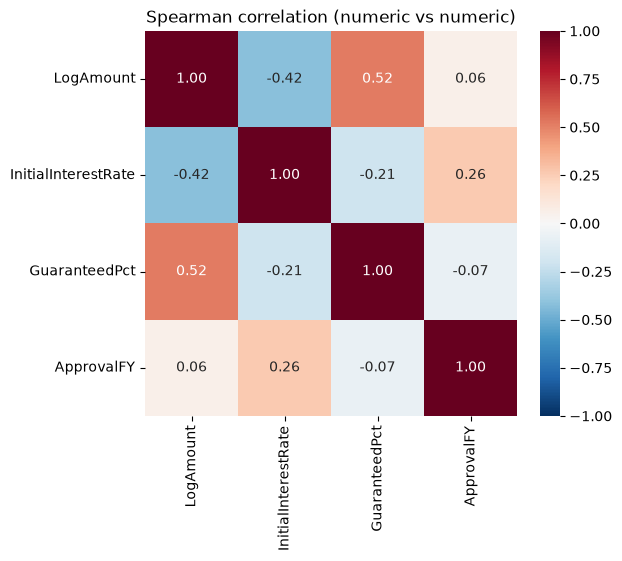

In [10]:
spearman = df[cols_num].rank().corr()

plt.figure(figsize=(6, 5))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlation (numeric vs numeric)")
plt.show()

### 2. Cramér's V (categorical – categorical)
We build the contingency table of the two variables and compare observed counts $O_{ij}$ with the counts expected under independence $E_{ij}$:

$$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \qquad E_{ij} = \frac{n_{i\cdot}\, n_{\cdot j}}{n}, \qquad V = \sqrt{\frac{\chi^2}{n\,(\min(r,k) - 1)}}$$

where $r$ and $k$ are the numbers of categories. Dividing by $n$ removes the effect of sample size (with 479k loans, $\chi^2$ alone would always be significant). $V = 0$ means independence and $V = 1$ means one variable fully determines the other. V is symmetric and has no direction.



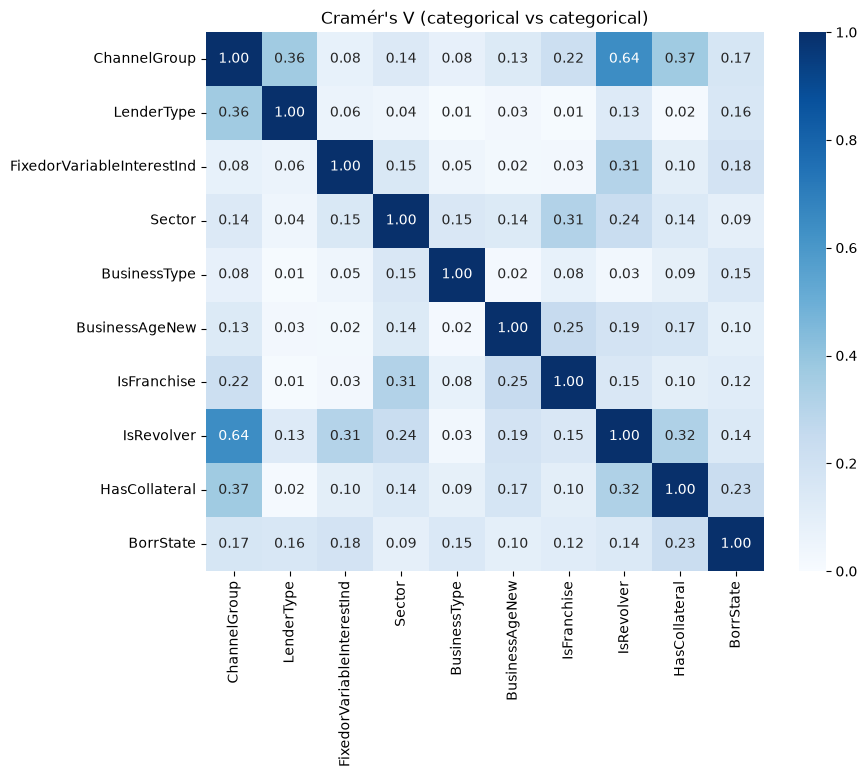

In [11]:
def cramers_v(x, y):
    t = pd.crosstab(x, y).to_numpy()
    n = t.sum()
    expected = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / n
    chi2 = ((t - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))

cramer = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cols_cat] for a in cols_cat],
                      index=cols_cat, columns=cols_cat)

plt.figure(figsize=(9, 7))
sns.heatmap(cramer, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cramér's V (categorical vs categorical)")
plt.show()

### 3. Correlation ratio η (categorical – numeric)
We split the numeric variable $y$ into the groups defined by the categorical variable and compare the variance **between** groups with the total variance:

$$\eta = \sqrt{\frac{\sum_g n_g\,(\bar{y}_g - \bar{y})^2}{\sum_i (y_i - \bar{y})^2}}$$

where $\bar{y}_g$ and $n_g$ are the mean and size of group $g$. $\eta^2$ is the share of the numeric variable's variance explained by the categories. $\eta = 0$ means all groups have the same mean, and $\eta = 1$ means the category fully determines the value. The matrix is rectangular (categories in rows, numeric variables in columns).

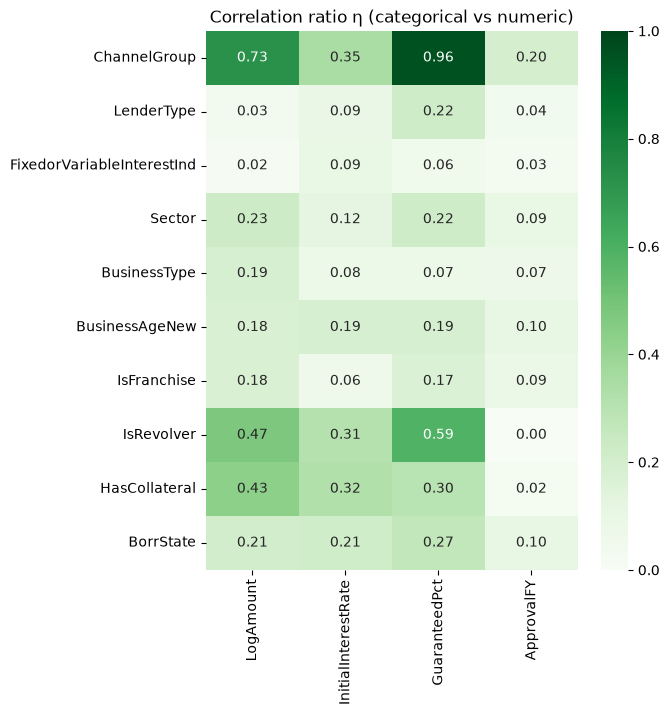

In [12]:
def eta(cat, num):
    g = num.groupby(cat)
    between = (g.count() * (g.mean() - num.mean()) ** 2).sum()
    total = ((num - num.mean()) ** 2).sum()
    return np.sqrt(between / total)

eta_matrix = pd.DataFrame([[eta(df[c], df[n]) for n in cols_num] for c in cols_cat],
                          index=cols_cat, columns=cols_num)

plt.figure(figsize=(6, 7))
sns.heatmap(eta_matrix, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1)
plt.title("Correlation ratio η (categorical vs numeric)")
plt.show()

### Distribution within each category (pairs with η ≥ 0.3)
A high η can come from groups that are all well separated, or from a single concentrated category while the others overlap. To tell the two cases apart, we plot the distribution of the numeric variable within each category for every pair with η ≥ 0.3.

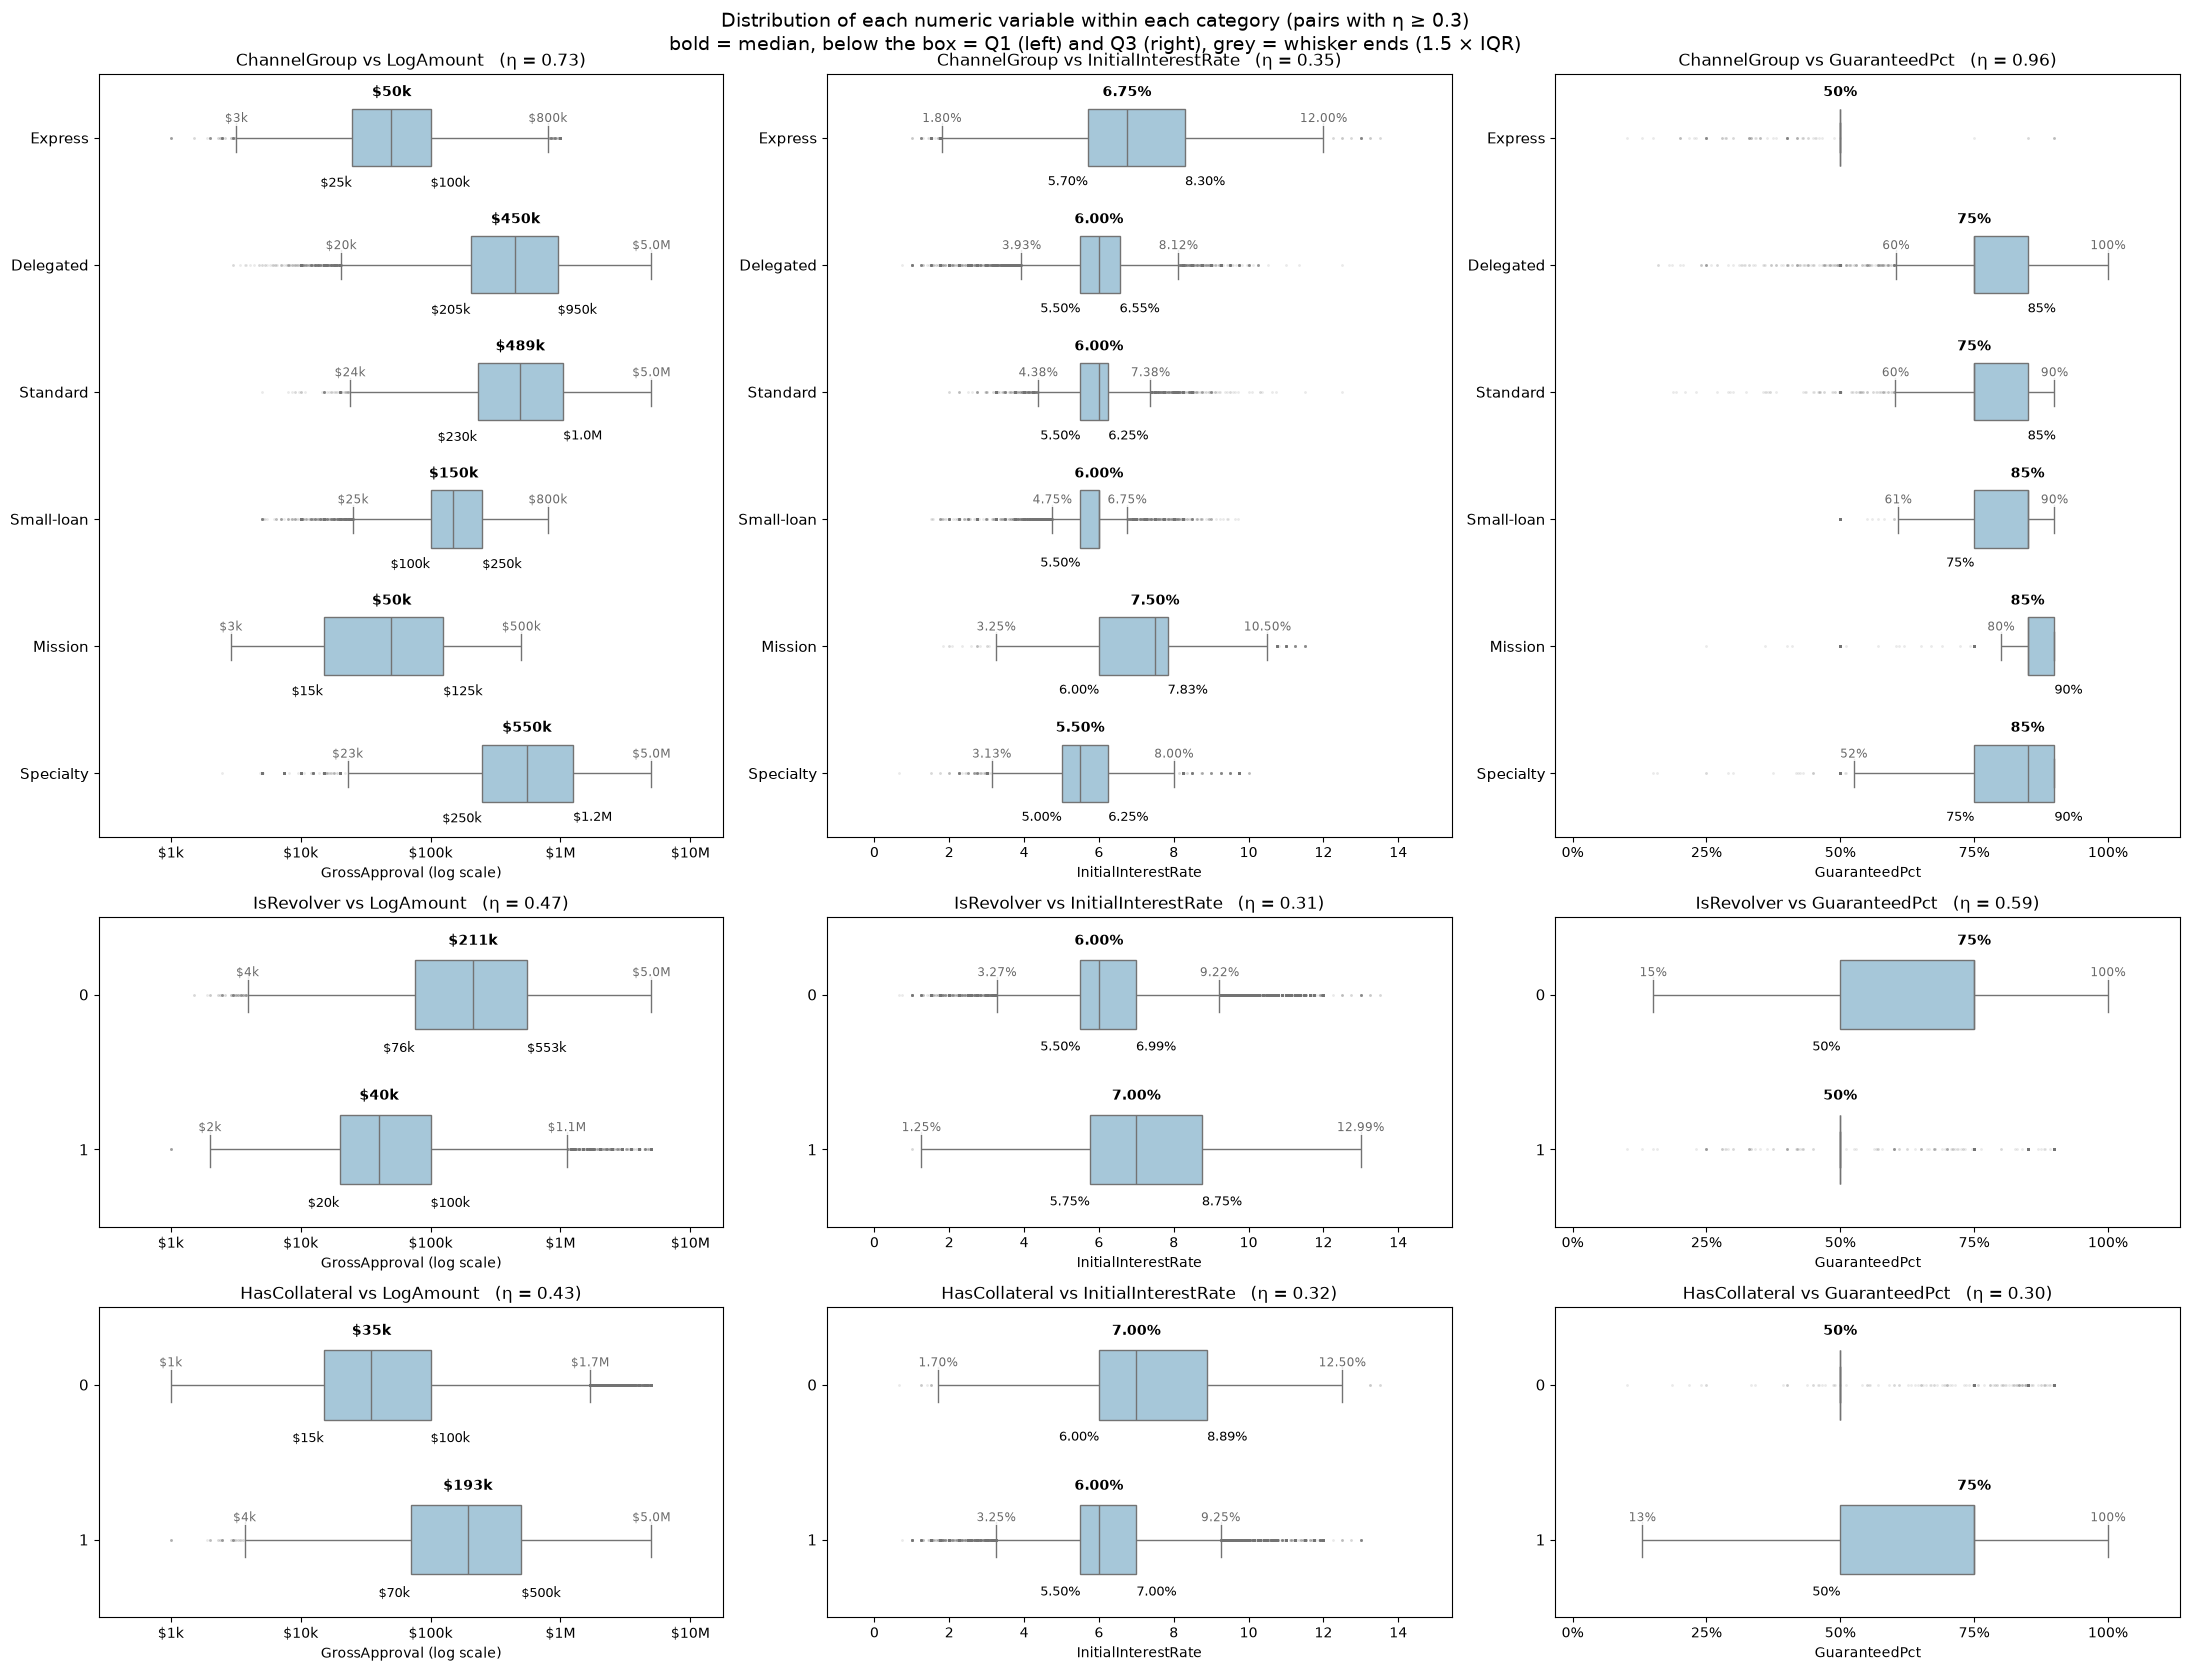

In [14]:
cat_vars = ["ChannelGroup", "IsRevolver", "HasCollateral"]
num_vars = ["LogAmount", "InitialInterestRate", "GuaranteedPct"]

# how to print values: amounts back in USD, rates in %, guarantee in %
fmt = {
    "LogAmount": lambda v: f"${10**v/1e6:.1f}M" if 10**v >= 1e6 else f"${10**v/1e3:.0f}k",
    "InitialInterestRate": lambda v: f"{v:.2f}%",
    "GuaranteedPct": lambda v: f"{v:.0%}",
}


def box_stats(values):
    """Whisker ends, Q1, median, Q3 as drawn by the boxplot (whiskers at 1.5 x IQR)."""
    q1, med, q3 = values.quantile([.25, .5, .75])
    iqr = q3 - q1
    low = values[values >= q1 - 1.5 * iqr].min()
    high = values[values <= q3 + 1.5 * iqr].max()
    return low, q1, med, q3, high


def annotate_box(ax, y, stats, f):
    low, q1, med, q3, high = stats
    bg = {"facecolor": "white", "edgecolor": "none", "pad": 0.6, "alpha": 0.85}  # readable over outlier dots
    ax.text(med, y - 0.3, f(med), ha="center", va="bottom", fontsize=10, fontweight="bold")  # median above
    if f(q1) != f(med):
        ax.text(q1, y + 0.3, f(q1), ha="right", va="top", fontsize=9)                       # Q1 below, left
    if f(q3) != f(med):
        ax.text(q3, y + 0.3, f(q3), ha="left", va="top", fontsize=9)                        # Q3 below, right
    if f(low) != f(q1):
        ax.text(low, y - 0.1, f(low), ha="center", va="bottom", fontsize=8.5, color="dimgray", bbox=bg)
    if f(high) != f(q3):
        ax.text(high, y - 0.1, f(high), ha="center", va="bottom", fontsize=8.5, color="dimgray", bbox=bg)


fig, axes = plt.subplots(len(cat_vars), len(num_vars), figsize=(22, 17),
                         gridspec_kw={"height_ratios": [3.2, 1.3, 1.3]})

for i, cat in enumerate(cat_vars):
    if df[cat].nunique() == 2:
        order = sorted(df[cat].unique())             # flags: 0 then 1
    else:
        order = df[cat].value_counts().index.tolist()
    for j, num in enumerate(num_vars):
        ax = axes[i, j]
        sns.boxplot(data=df, x=num, y=cat, order=order, orient="h", ax=ax,
                    color="#9ecae1", width=0.45,
                    flierprops={"marker": ".", "markersize": 2, "alpha": 0.15})
        for y, level in enumerate(order):
            annotate_box(ax, y, box_stats(df.loc[df[cat] == level, num]), fmt[num])
        lo, hi = df[num].min(), df[num].max()
        ax.set_xlim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))   # room for the whisker labels
        ax.set_title(f"{cat} vs {num}   (η = {eta_matrix.loc[cat, num]:.2f})", fontsize=12)
        ax.set_ylabel("")
        ax.tick_params(axis="y", labelsize=11)
        if num == "LogAmount":                       # show the log axis in dollars
            ax.set_xticks([3, 4, 5, 6, 7], ["$1k", "$10k", "$100k", "$1M", "$10M"])
            ax.set_xlabel("GrossApproval (log scale)")
        if num == "GuaranteedPct":
            ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])

fig.suptitle("Distribution of each numeric variable within each category (pairs with η ≥ 0.3)\n"
             "bold = median, below the box = Q1 (left) and Q3 (right), grey = whisker ends (1.5 × IQR)",
             fontsize=14)
plt.tight_layout()
plt.show()

#### Conclusions on the η ≥ 0.3 pairs

**ChannelGroup → GrossApproval (η = 0.73).** Channels form three clear size tiers: small loans in Express and Mission (median $50k), medium loans in Small-loan ($150k) and large loans in Delegated, Standard and Specialty ($450k–$550k). The boxes of different tiers barely overlap and the spread is similar within each channel, so the whole variable explains loan size, not a single category.

**ChannelGroup → InitialInterestRate (η = 0.35).** Delegated, Standard, Small-loan and Specialty price almost identically (medians 5.50–6.00%, narrow boxes). Only Express (median 6.75%, IQR 5.70–8.30%) and Mission (7.50%) stand apart, and Express also shows the widest spread. The association comes from these two channels, not from the variable as a whole.

**ChannelGroup → GuaranteedPct (η = 0.96).** Express loans are all guaranteed at 50%, while the other channels lie between 75% and 90% (Mission highest, 85–90%). The very high η is driven by Express being a separate block, which reflects SBA program rules. Outside Express the guarantee varies little, so `GuaranteedPct` adds almost no information beyond the channel.

**IsRevolver → GrossApproval (η = 0.47).** Revolving lines are much smaller (median $40k, IQR $20k–$100k) than term loans ($211k, IQR $76k–$553k). The whole distribution shifts, with only a narrow overlap between the two boxes.

**IsRevolver → InitialInterestRate (η = 0.31).** Revolvers pay more (median 7.00% vs 6.00%) and their rates are more dispersed (IQR 5.75–8.75% vs 5.50–6.99%). The boxes overlap substantially, so the link is moderate.

**IsRevolver → GuaranteedPct (η = 0.59).** Revolvers are concentrated at a 50% guarantee, while term loans range from 50% to 75%. As with Express, a single concentrated category drives η, which suggests most revolvers are Express loans (consistent with Cramér's V = 0.64 between the two).

**HasCollateral → GrossApproval (η = 0.43).** Loans without collateral are small (median $35k, IQR $15k–$100k), while secured loans are larger ($193k, IQR $70k–$500k). Collateral is mostly required on bigger loans.

**HasCollateral → InitialInterestRate (η = 0.32).** Unsecured loans pay more (median 7.00% vs 6.00%) and show a wider spread. This is consistent with risk-based pricing, but it may also reflect loan size, since unsecured loans are smaller.

**HasCollateral → GuaranteedPct (η = 0.30).** Despite the lowest η, the pattern is sharp: unsecured loans sit almost entirely at 50%, while secured loans range from 50% to 75%. η stays moderate only because many secured loans also have a 50% guarantee.

**Overall.** The pairs describe one recurring profile: **Express loans are small, often revolving, unsecured, guaranteed at 50% and priced higher.**

## Associations with Default
We now measure how each feature is related to the target. We use the χ² test and Cramér's V for categorical features, and the Spearman correlation for numeric features.

### 4. Categorical features vs Default: χ² test and Cramér's V
The χ² test tells us **whether** the default rate differs across categories (H0: the feature and Default are independent). Cramér's V tells us **how strong** the association is.


In [ ]:
rows = []
for col in cols_cat:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[col], df["Default"]))
    rows.append({"variable": col, "chi2": chi2, "dof": dof, "p_value": p,
                 "cramers_v": cramers_v(df[col], df["Default"])})

chi_default = pd.DataFrame(rows).set_index("variable").sort_values("cramers_v", ascending=False)
chi_default.round(4)

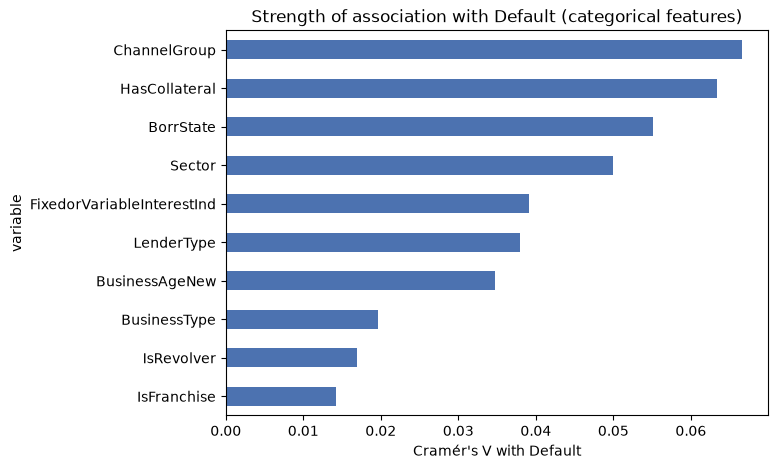

In [17]:
chi_default["cramers_v"].sort_values().plot.barh(figsize=(7, 5), color="#4c72b0")
plt.xlabel("Cramér's V with Default")
plt.title("Strength of association with Default (categorical features)")
plt.show()

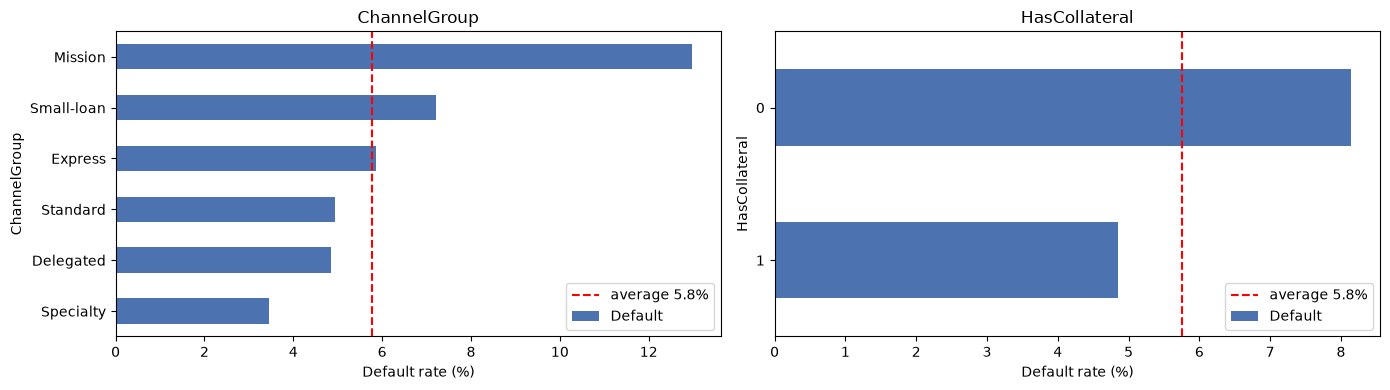

In [18]:
base = df["Default"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["ChannelGroup", "HasCollateral"]):
    rates = df.groupby(col)["Default"].mean().sort_values() * 100
    rates.plot.barh(ax=ax, color="#4c72b0")
    ax.axvline(base, color="red", ls="--", label=f"average {base:.1f}%")
    ax.set_xlabel("Default rate (%)")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Sector has 20 categories, so we plot it separately. Bars with fewer than 1,000 loans are lighter.
counts = df["Sector"].value_counts()
rates = df.groupby("Sector")["Default"].mean().sort_values() * 100
colors = ["#4c72b0" if counts[s] >= 1000 else "#c6d4e9" for s in rates.index]

ax = rates.plot.barh(figsize=(9, 7), color=colors)
ax.axvline(base, color="red", ls="--", label=f"average {base:.1f}%")
ax.set_xlabel("Default rate (%)")
ax.set_title("Sector (lighter bars: fewer than 1,000 loans)")
ax.legend()
plt.tight_layout()
plt.show()

#### Conclusions: categorical features vs Default
All variables are significantly associated with default (χ² test, p < 0.001), as expected with 479k loans. Cramér's V is low for every variable because the target is rare (5.8%), so we use it to **rank** the variables rather than to judge them in absolute terms.

- **ChannelGroup** (V = 0.067) and **HasCollateral** (V = 0.063) show the strongest association. Mission loans default at 13.0%, more than twice the 5.8% average, while Specialty (3.5%), Delegated (4.9%) and Standard (5.0%) are below it. Loans without collateral default at 8.1% versus 4.9% with collateral.
- **BorrState** (V = 0.055) and **Sector** (V = 0.050) follow. Among sectors, Transportation (7.6%), Arts & Recreation (7.3%) and Retail (6.6%) are riskiest, while Health Care (3.5%) and Agriculture (2.9%) are safest. Very small sectors (Management of Companies, Utilities, Public Administration) are based on few loans and should not be over-interpreted.
- **IsRevolver** (V = 0.017) and **IsFranchise** (V = 0.014) show the weakest association (6.4% vs 5.5% and 6.8% vs 5.7%).

### 5. Numeric features vs Default: Spearman correlation
χ² and Cramér's V only apply to categorical variables, so for numeric features we use the Spearman correlation with Default. The sign gives the direction: positive means higher values go with more defaults.

LogAmount             -0.075
ApprovalFY             0.012
GuaranteedPct          0.020
InitialInterestRate    0.110
dtype: float64

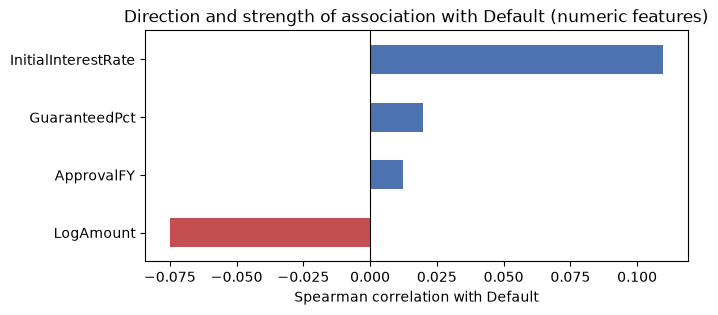

In [19]:
spearman_default = df[cols_num].rank().corrwith(df["Default"]).sort_values()
display(spearman_default.round(3))

spearman_default.plot.barh(figsize=(7, 3),
                           color=["#c44e52" if v < 0 else "#4c72b0" for v in spearman_default])
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Spearman correlation with Default")
plt.title("Direction and strength of association with Default (numeric features)")
plt.show()

In [20]:
df["RateBand"] = pd.cut(df["InitialInterestRate"], [0, 5, 6, 7, 8, 14],
                        labels=["<5%", "5-6%", "6-7%", "7-8%", "8%+"])
df["AmountBand"] = pd.cut(df["GrossApproval"], [0, 50e3, 150e3, 500e3, 5.1e6],
                          labels=["<50k", "50-150k", "150-500k", "500k+"])

for band in ["RateBand", "AmountBand"]:
    t = df.groupby(band, observed=True)["Default"].agg(["count", "mean"])
    t["mean"] = t["mean"] * 100
    display(t.rename(columns={"mean": "default_rate_%"}).round(2))

,count,default_rate_%
RateBand,,
<5%,63213,2.18
5-6%,183621,4.35
6-7%,90962,6.05
7-8%,68169,8.06
8%+,72991,9.90


,count,default_rate_%
AmountBand,,
<50k,160592,7.40
50-150k,112776,6.89
150-500k,112315,4.98
500k+,93273,2.52


#### Conclusions: numeric features vs Default
- **InitialInterestRate** has the strongest association of all features (ρ = +0.110). The default rate rises steadily with the rate band, from 2.2% below 5% to 9.9% above 8%.
- **GrossApproval** goes the other way (ρ = −0.075): larger loans default less, from 7.4% below $50k to 2.5% above $500k.
- **GuaranteedPct** (ρ = +0.020) and **ApprovalFY** (ρ = +0.012) show almost no direct association with default.

## Summary of results

### 1. Redundant features
- **`GuaranteedPct` is almost fully determined by `ChannelGroup` (η = 0.96).** Express loans are all guaranteed at 50%, while the other channels lie between 75% and 90%. In the models we should keep only one of the two, or interpret them together.
- **One recurring "Express profile" links several features.** Express loans are small (median $50k), often revolving (Cramér's V channel–revolver = 0.64), unsecured, guaranteed at 50% and priced higher. As a result, `ChannelGroup`, `IsRevolver`, `HasCollateral`, `GuaranteedPct` and loan size partly carry the same information.
- **Loan size is linked to most financing features:** to the guarantee (ρ = 0.52), to the interest rate (ρ = −0.42, smaller loans pay more), to collateral (η = 0.43) and to revolver status (η = 0.47).
- **Some associations come from a single category.** A high η or V does not always mean the whole variable matters. For the guarantee, only Express (and, equivalently, revolvers and unsecured loans) stands apart, while the other categories overlap.
- **The remaining features are only weakly related to each other** (V and η mostly below 0.3), so they bring separate information.

### 2. Features associated with default
Default is rare (5.8%), so all associations are weak in absolute terms. They are, however, all statistically significant and economically relevant.

| Rank | Feature | Measure | Direction / key numbers |
|---|---|---|---|
| 1 | InitialInterestRate | ρ = +0.110 | 2.2% (< 5%) → 9.9% (≥ 8%) |
| 2 | GrossApproval | ρ = −0.075 | 7.4% (< $50k) → 2.5% (≥ $500k) |
| 3 | ChannelGroup | V = 0.067 | Mission 13.0%, Specialty 3.5% |
| 4 | HasCollateral | V = 0.063 | 8.1% without vs 4.9% with |
| 5 | BorrState | V = 0.055 | from about 3% (ND, ME) to 8.6% (FL) |
| 6 | Sector | V = 0.050 | Transportation 7.6%, Agriculture 2.9% |
| 7 | Others | V < 0.04 | e.g. non-bank lenders 10.0%, variable rate 6.2% vs fixed 4.0% |

ρ and V are built differently, so we compare them only indicatively.

### 3. Implications for modelling
- We should drop `GuaranteedPct` or `ChannelGroup` (or test both versions), because they are nearly redundant.
- In tree-based models and SHAP values, correlated features split their importance. We should therefore read the importance of the Express-profile features **as a group**.
- The interest rate is the strongest single signal, but it is set by the lender based on its own risk assessment. Part of its predictive power reflects the lender's judgement rather than the borrower alone.

### 4. Limits and next steps
- These are **pairwise** associations: they do not control for other variables. For example, the collateral effect may partly reflect loan size, since unsecured loans are smaller. The next step is to check the main effects **within** the same channel and loan size, using default-rate maps for pairs of features.
- **Time effects** are not covered yet. Interest rates rise over the period (ρ rate–year = 0.26), so the meaning of a given rate may change across years. We should check this before using the rate in an out-of-time validation.
- Associations are **not causal**: they describe which loans default more, not why.